# D2 · Ler e limpar un CSV meteorolóxico

**Sistemas de Big Data · UD1 · Tema 2**

Os datos abertos raramente chegan listos para analizar. Este ficheiro reproduce os problemas máis habituais das descargas de portais públicos españois e galegos:

- codificación Latin-1 en lugar de UTF-8
- liñas de metadatos antes da cabeceira
- separador `;` e decimal con coma
- datas en formato día/mes/ano
- valores ausentes codificados de varias maneiras
- duplicados e valores imposibles

> Os datos son **sintéticos**, xerados para practicar. No P1 traballaredes con datos reais.

## 1. Primeiro intento

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUTA = Path("datos/meteo_coruna_2024_sucio.csv")

try:
    pd.read_csv(RUTA)
except Exception as e:
    print(type(e).__name__, "→", e)

UnicodeDecodeError → 'utf-8' codec can't decode byte 0xf3 in position 6: invalid continuation byte


**Problema 1: a codificación.** O ficheiro non está en UTF-8. Miramos os primeiros bytes para descubrilo:

In [12]:
print(RUTA.read_bytes()[:120])

b'Estaci\xf3n: A Coru\xf1a (exemplo did\xe1ctico, datos sint\xe9ticos)\nPer\xedodo: 01/01/2024 - 31/12/2024\nFonte: elaboraci\xf3n propia para'


Os bytes `\xf3` (ó) ou `\xba` (º) indican **Latin-1** (ISO-8859-1). En UTF-8 eses caracteres ocuparían dous bytes. Probamos de novo:

In [3]:
with open(RUTA, encoding="latin-1") as f:
    for _ in range(6):
        print(f.readline().rstrip())

Estación: A Coruña (exemplo didáctico, datos sintéticos)
Período: 01/01/2024 - 31/12/2024
Fonte: elaboración propia para o módulo de Sistemas de Big Data

Data;Temperatura media (ºC);Temperatura máxima (ºC);Temperatura mínima (ºC);Precipitación (l/m²);Vento medio (km/h);Humidade relativa (%)
01/01/2024;10,9;14,3;7,6;7,6;13,8;80


**Problema 2: metadatos.** As catro primeiras liñas non son datos. A cabeceira real está na quinta liña (índice 4), así que saltamos as catro primeiras.

## 2. Lectura correcta

In [4]:
meteo = pd.read_csv(
    RUTA,
    encoding="latin-1",
    skiprows=4,
    sep=";",
    decimal=",",
    na_values=["-", ""],
)
meteo.head()

,Data,Temperatura media (ºC),Temperatura máxima (ºC),Temperatura mínima (ºC),Precipitación (l/m²),Vento medio (km/h),Humidade relativa (%)
0,01/01/2024,10.9,14.3,7.6,7.6,13.8,80.0
1,02/01/2024,7.1,11.0,3.7,8.1,7.5,91.0
2,03/01/2024,10.5,13.6,7.0,4.8,24.1,79.0
3,04/01/2024,10.5,14.8,7.3,1.9,NaN,85.0
4,05/01/2024,10.1,16.1,5.9,0.7,7.0,85.0


In [5]:
meteo.info()

<class 'pandas.DataFrame'>
RangeIndex: 368 entries, 0 to 367
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Data                     368 non-null    str    
 1   Temperatura media (ºC)   368 non-null    float64
 2   Temperatura máxima (ºC)  366 non-null    float64
 3   Temperatura mínima (ºC)  367 non-null    float64
 4   Precipitación (l/m²)     362 non-null    float64
 5   Vento medio (km/h)       366 non-null    float64
 6   Humidade relativa (%)    364 non-null    float64
dtypes: float64(6), str(1)
memory usage: 20.3 KB


**Problema 3: nomes de columnas.** Con acentos, espazos e unidades son incómodos de usar en código. Renomeámolos:

In [6]:
meteo = meteo.rename(columns={
    "Data": "data",
    "Temperatura media (ºC)": "tmed",
    "Temperatura máxima (ºC)": "tmax",
    "Temperatura mínima (ºC)": "tmin",
    "Precipitación (l/m²)": "prec",
    "Vento medio (km/h)": "vento",
    "Humidade relativa (%)": "hum",
})
meteo.columns.tolist()

['data', 'tmed', 'tmax', 'tmin', 'prec', 'vento', 'hum']

**Problema 4: as datas.** `data` é texto. Convertémola indicando o formato día/mes/ano para evitar confundir o 03/04 co 4 de marzo:

In [7]:
meteo["data"] = pd.to_datetime(meteo["data"], format="%d/%m/%Y")
meteo.dtypes

data     datetime64[us]
tmed            float64
tmax            float64
tmin            float64
prec            float64
vento           float64
hum             float64
dtype: object

## 3. Limpeza

In [8]:
# Problema 5: duplicados
print("Filas duplicadas:", meteo.duplicated().sum())
print("Datas repetidas:", meteo["data"].duplicated().sum())
meteo = meteo.drop_duplicates()

Filas duplicadas: 2
Datas repetidas: 2


In [9]:
# Problema 6: valores imposibles
meteo.describe().round(1)

,data,tmed,tmax,tmin,prec,vento,hum
count,366,366.0,364.0,365.0,360.0,364.0,362.0
mean,2024-07-01 12:00:00,19.4,18.3,10.0,4.6,14.3,79.8
min,2024-01-01 00:00:00,5.9,9.8,0.4,-5.0,0.4,60.0
25%,2024-04-01 06:00:00,11.2,15.7,7.0,0.0,10.1,75.0
50%,2024-07-01 12:00:00,14.0,18.5,10.2,1.9,14.3,80.0
75%,2024-09-30 18:00:00,17.1,21.2,13.1,6.8,18.1,84.8
max,2024-12-31 00:00:00,999.9,28.0,18.1,48.9,30.4,99.0
std,NaN,72.9,3.7,3.5,6.9,5.8,7.2


Unha temperatura media de 999,9 ºC ou unha precipitación negativa non son posibles. Adoitan ser **códigos de erro do sensor**. Substituímolos por nulos:

In [10]:
imposibles = (meteo["tmed"] > 50) | (meteo["prec"] < 0)
print("Valores imposibles:", imposibles.sum())
meteo.loc[meteo["tmed"] > 50, "tmed"] = pd.NA
meteo.loc[meteo["prec"] < 0, "prec"] = pd.NA

Valores imposibles: 3


In [11]:
# Problema 7: nulos
meteo.isna().sum()

data     0
tmed     2
tmax     2
tmin     1
prec     7
vento    2
hum      4
dtype: int64

Que facemos cos nulos? Depende da análise. Opcións habituais:

- **eliminar** a fila (perdemos información)
- **interpolar** desde os días veciños (razoable en temperaturas)
- **deixalos** e telo en conta ao agregar

Para a temperatura interpolamos. Para a precipitación deixámolos, porque inventar choiva é peor ca non ter o dato.

In [12]:
meteo = meteo.set_index("data").sort_index()
for col in ["tmed", "tmax", "tmin", "vento", "hum"]:
    meteo[col] = meteo[col].interpolate(method="time")
meteo.isna().sum()

tmed     0
tmax     0
tmin     0
prec     7
vento    0
hum      0
dtype: int64

## 4. Primeira análise rápida

In [13]:
mensual = meteo.resample("MS").agg({"tmed": "mean", "prec": "sum"})
MESES = ["xan", "feb", "mar", "abr", "mai", "xuñ", "xul", "ago", "set", "out", "nov", "dec"]
mensual.index = [MESES[m - 1] for m in mensual.index.month]
mensual.round(1)

,tmed,prec
xan,9.4,220.6
feb,9.9,180.5
mar,11.8,200.6
abr,13.8,173.8
mai,16.2,103.6
xuñ,17.5,59.4
xul,18.5,89.6
ago,17.8,132.1
set,16.4,57.0
out,14.5,160.3


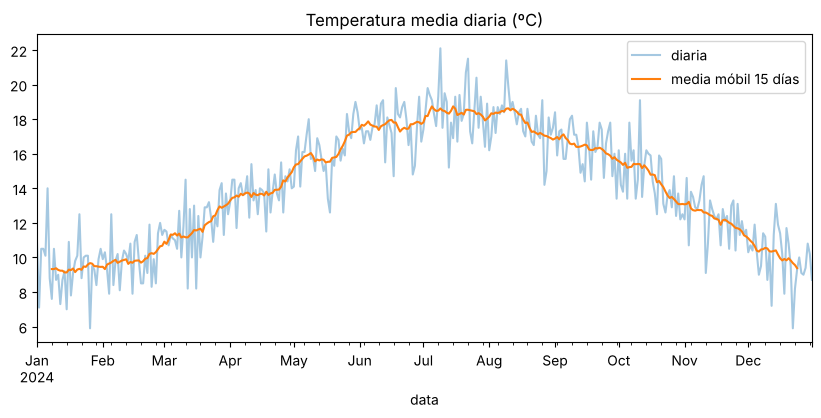

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
meteo["tmed"].plot(ax=ax, alpha=0.4, label="diaria")
meteo["tmed"].rolling(15, center=True).mean().plot(ax=ax, label="media móbil 15 días")
ax.set_title("Temperatura media diaria (ºC)")
ax.legend()
plt.show()

## 5. Gardar os datos limpos

In [15]:
limpo = Path("../datos/clean")
limpo.mkdir(exist_ok=True)
meteo.to_csv(limpo / "meteo_coruna_2024.csv")   # UTF-8, separador "," e decimal "."
print("Gardado:", limpo / "meteo_coruna_2024.csv")

Gardado: ../datos/clean/meteo_coruna_2024.csv


Gardámolo nun formato **estándar**: UTF-8, coma como separador e punto decimal. Así calquera ferramenta o le sen sorpresas. O ficheiro orixinal queda intacto en *raw*: **nunca se modifican os datos de orixe**.

## 6. E con datos reais?

No P1 obteredes datos reais coa libraría [Meteostat](https://dev.meteostat.net/python) (versión 2.x). Precisa conexión a Internet. Exemplo:

```python
# pip install meteostat
from datetime import date
import meteostat as ms

coruna = ms.Point(43.37, -8.42, 50)
estacions = ms.stations.nearby(coruna, limit=3)   # estacións próximas
print(estacions)

ts = ms.daily(ms.Station(id="ID_DA_ESTACION"), date(2024, 1, 1), date(2024, 12, 31))
df = ts.fetch()   # columnas: temp, tmin, tmax, prcp, wspd, pres...
```

Comparade o que devolve Meteostat co ficheiro deste notebook: que problemas desaparecen e cales seguen aí?